## Create csv file if not exist

In [1]:
import os
print(os.listdir("./"))
print(os.getcwd())

['.ipynb_checkpoints', 'PRE-TRAINED-SAFE-FILES', 'result', 'yolo-from-scratch-final.ipynb', 'YOLO_FROM_SCRATCH.ipynb', 'Yolo_Test_Data']
D:\3DSF\computer-vision\yolo-from-scratch


In [2]:
import os
import csv

def get_all_file_names(directory):
    file_names = os.listdir(directory)
    return file_names

def create_dataset(min_idx, max_idx, csv_name, file_names, dist_path):

    with open(f"{dist_path}/{csv_name}.csv", mode="w", newline="") as csv_file:
        for i, fl_name in enumerate(file_names[min_idx:max_idx+1]):
            name = fl_name.split(".")[0]
            img_name = name+".jpg"
            label_name = name+".txt"
            data = [img_name, label_name]
            writer = csv.writer(csv_file)
            writer.writerow(data)


directory_path = "./Yolo_Test_Data/annotations"
dist_path="./Yolo_Test_Data/"

file_names = get_all_file_names(directory_path)

train_size = [0, int(0.8 * len(file_names))+1]
test_size = [train_size[0], int(0.2 * len(file_names))+1]
val_size = [test_size[0], int(0.2 * len(file_names))+1]


create_dataset(min_idx=train_size[0], max_idx=train_size[1], csv_name="big_train",file_names=file_names, dist_path=dist_path)
create_dataset(min_idx=test_size[0], max_idx=test_size[1], csv_name="big_test",file_names=file_names, dist_path=dist_path)
create_dataset(min_idx=val_size[0], max_idx=val_size[1], csv_name="big_val",file_names=file_names, dist_path=dist_path)


create_dataset(min_idx=0, max_idx=101, csv_name="tiny_train",file_names=file_names, dist_path=dist_path)
create_dataset(min_idx=101, max_idx=121, csv_name="tiny_test",file_names=file_names,dist_path=dist_path)
create_dataset(min_idx=121, max_idx=141, csv_name="tiny_val",file_names=file_names, dist_path=dist_path)

## import required libraries

In [3]:
import torch
import torch.nn as nn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torchvision.transforms as transforms
import torch.optim as optim
import torchvision.transforms.functional as FT
from tqdm import tqdm
import matplotlib.patches as patches
from collections import Counter
from PIL import Image
import os
from torch.utils.data import DataLoader
import time
import cv2
import sympy

## dataloader (load data in batchs)

In [4]:
class TSDataSet(torch.utils.data.Dataset):
    def __init__(self, csv_file, img_dir, label_dir, split_size, n_box, n_class, transform=None):
        self.annotations = pd.read_csv(csv_file)
        self.img_dir = img_dir
        self.label_dir = label_dir
        self.transform = transform
        self.S = split_size
        self.B = n_box
        self.C = n_class

    def __len__(self):
        return len(self.annotations)

    def __getitem__(self, index):
        # get label
        label_path = os.path.join(self.label_dir, self.annotations.iloc[index, 1])
        boxes = []
        with open(label_path) as f:
            for label in f.readlines():
                class_label, x, y, w, h = [
                    float(x) if float(x) != int(float(x)) else int(x)
                    for x in label.replace("\n", "").split()
                ]
                boxes.append([class_label, x, y, w, h])
        # get img
        img_path = os.path.join(self.img_dir, self.annotations.iloc[index, 0])
        image = Image.open(img_path)
        boxes = torch.tensor(boxes)

        if self.transform:
            image, boxes = self.transform(image, boxes)

        # convert (x, y, h, w) to cell dims
        label_matrix = torch.zeros((self.S, self.S, self.C + 5 * self.B))
        for box in boxes:
            class_label, x, y, w, h = box.tolist()
            class_label = int(class_label)
        
            # i cell, j cell
            i, j = int(self.S * y), int(self.S * x)
            x_cell, y_cell = self.S * x - j, self.S * y - i

            width_cell, height_cell = (
                w * self.S,
                h * self.S,
            )

            # in case not object found ( we suppose that there is one object per cell )
            if label_matrix[i, j, self.C] == 0:
                label_matrix[i, j, self.C] = 1 # marked is done (there is an object) (prob = 1)
                label_matrix[i, j, self.C+1:self.C+5] = torch.tensor([x_cell, y_cell, width_cell, height_cell])
                label_matrix[i, j, class_label] = 1

        return image, label_matrix

## Yolo v1 architecture

#YOLO architecture


<center>
  <img src="https://github-production-user-asset-6210df.s3.amazonaws.com/89405673/256159753-2d92089b-4235-4505-879f-3a1f4c854e68.png" />
</center>

> architecture configuration

In [5]:
#yolo architecture configuration
conv_layers_config = [
    (64, 7, 2, 3), # (n_filters, kernel_size, stride, padding)
    "M",           # Max Pooling
    (192, 3, 1, 1),
    "M",
    (128, 1, 1, 0),
    (256, 3, 1, 1),
    (256, 1, 1, 0),
    (512, 3, 1, 1),
    "M",
    [(256, 1, 1, 0), (512, 3, 1, 1), 4],
    (512, 1, 1, 0),
    (1024, 3, 1, 1),
    "M",
    [(512, 1, 1, 0), (1024, 3, 1, 1), 2],
    (1024, 3, 1, 1),
    (1024, 3, 2, 1),
    (1024, 3, 1, 1),
    (1024, 3, 1, 1),
]

> CNN Block (the building block of yolo architecture)

In [6]:
class CNNBlock(nn.Module):
    def __init__(self,in_channels, out_channels, **kwargs):
        super(CNNBlock, self).__init__()
        self.conv = nn.Conv2d(in_channels, out_channels, bias=False, **kwargs)
        self.batchnorm = nn.BatchNorm2d(out_channels)
        self.leakyrelu = nn.LeakyReLU(0.1)

    def forward(self, x):
        return self.leakyrelu(self.batchnorm(self.conv(x)))

> Now, Let's build the baby yolo model (Note : i am try to implement yolo v1 here)

In [7]:
class Baby_Yolo(nn.Module):
    def __init__(self,in_channels=3, **kwargs):
        super(Baby_Yolo, self).__init__()
        self.arch_config = conv_layers_config
        self.in_channels = in_channels
        self.darknet = self.__create_cnn_layers_from_config(self.arch_config)
        self.fcnns_layer = self.__create_fcnns_layer(**kwargs)

    def forward(self, x):
        x = self.darknet(x)
        return self.fcnns_layer(torch.flatten(x, start_dim=1))

    def __create_cnn_layers_from_config(self, arch_config):
        layers = []
        in_channels = self.in_channels

        for LC in arch_config:
            if type(LC) == tuple:
                layers += [ CNNBlock(in_channels, LC[0], kernel_size=LC[1], stride=LC[2], padding=LC[3],) ]
                in_channels = LC[0]

            elif type(LC) == str:
                layers += [nn.MaxPool2d(kernel_size=(2, 2), stride=(2, 2))]

            elif type(LC) == list:
                lc1 = LC[0]
                lc2 = LC[1]
                n_times = LC[2]

                for _ in range(n_times):
                    layers += [ CNNBlock(in_channels,lc1[0],kernel_size=lc1[1],stride=lc1[2],padding=lc1[3]) ]
                    layers += [ CNNBlock(lc1[0],lc2[0],kernel_size=lc2[1],stride=lc2[2],padding=lc2[3]) ]
                    in_channels = lc2[0]

        return nn.Sequential(*layers)


    def __create_fcnns_layer(self, split_size, n_box, n_class):
        SS = split_size
        return nn.Sequential(
            nn.Flatten(),
            nn.Linear(1024 * SS * SS, 496),
            nn.Dropout(0.0),
            nn.LeakyReLU(0.1),
            nn.Linear(496, SS * SS * (n_class + n_box * 5)),
        )

> IoU : Intersection over union

<center>
  <img src="https://github.com/benisalla/Calculator/assets/89405673/5da49c3e-4543-4125-9763-2f0f8eff494e" width="500" height="200"/>
</center>

In [8]:
#====================================#
#       intersection_over_union      #
#====================================#

def intersection_over_union(boxes_preds, boxes_labels, box_format="midpoint"):
    if box_format == "midpoint":
        box1_x1 = boxes_preds[..., 0:1] - boxes_preds[..., 2:3] / 2
        box1_y1 = boxes_preds[..., 1:2] - boxes_preds[..., 3:4] / 2
        box1_x2 = boxes_preds[..., 0:1] + boxes_preds[..., 2:3] / 2
        box1_y2 = boxes_preds[..., 1:2] + boxes_preds[..., 3:4] / 2
        box2_x1 = boxes_labels[..., 0:1] - boxes_labels[..., 2:3] / 2
        box2_y1 = boxes_labels[..., 1:2] - boxes_labels[..., 3:4] / 2
        box2_x2 = boxes_labels[..., 0:1] + boxes_labels[..., 2:3] / 2
        box2_y2 = boxes_labels[..., 1:2] + boxes_labels[..., 3:4] / 2

    if box_format == "corners":
        box1_x1 = boxes_preds[..., 0:1]
        box1_y1 = boxes_preds[..., 1:2]
        box1_x2 = boxes_preds[..., 2:3]
        box1_y2 = boxes_preds[..., 3:4]
        box2_x1 = boxes_labels[..., 0:1]
        box2_y1 = boxes_labels[..., 1:2]
        box2_x2 = boxes_labels[..., 2:3]
        box2_y2 = boxes_labels[..., 3:4]

    x1 = torch.max(box1_x1, box2_x1)
    y1 = torch.max(box1_y1, box2_y1)
    x2 = torch.min(box1_x2, box2_x2)
    y2 = torch.min(box1_y2, box2_y2)

    ii = (x2 - x1).clamp(0) * (y2 - y1).clamp(0)
    box1_area = abs((box1_x2 - box1_x1) * (box1_y2 - box1_y1))
    box2_area = abs((box2_x2 - box2_x1) * (box2_y2 - box2_y1))

    return ii / (box1_area + box2_area - ii + 1e-6)


#====================================#
#        non_max_suppression         #
#====================================#

def non_max_suppression(bboxes, iou_threshold, drop_threshold, box_format="corners"):
    ''' boxes = [[class, prob, x1, y1, x2, y2], [class, prob, x1, y1, x2, y2]]'''
    assert type(bboxes) == list
    # drop boxes with obj_prob < drop_threshold
    bboxes = [box for box in bboxes if box[1] > drop_threshold]
    # sort boxes according to there threshold box0.p > box1.p > ... > boxn.p
    bboxes = sorted(bboxes, key=lambda x: x[1], reverse=True)

    filtered_boxes = []
    while bboxes:
        chosen_box = bboxes.pop(0)
        bboxes = [
            box for box in bboxes if box[0] != chosen_box[0]
            or intersection_over_union( torch.tensor(chosen_box[2:]), torch.tensor(box[2:]), box_format=box_format
                                       ) < iou_threshold  # this exactly why it is called non max suppresion
        ]
        filtered_boxes.append(chosen_box)
    return filtered_boxes


#====================================#
#        mean_average_precision      #
#====================================#

def mean_average_precision(
    pred_boxes, true_boxes, iou_threshold=0.5, box_format="midpoint", n_class=20 # i should change this later !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
):
    ''' pred_boxes = [img_idx, class_idx, prob, x1, y1, x2, y2] '''
    # list of average precisions
    average_precisions = []

    # just for numerical stability
    epsilon = 1e-6

    for class_idx in range(n_class):
        detected_bboxes = []
        grd_truths = []

        # get preds and targets related to class_idx
        for detected_bbox in pred_boxes:
            if detected_bbox[1] == class_idx:
                detected_bboxes.append(detected_bbox)

        for true_box in true_boxes:
            if true_box[1] == class_idx:
                grd_truths.append(true_box)

        # box_freq_per_img : {img_id: freq_boxes}
        box_freq_per_img = Counter([grdT[0] for grdT in grd_truths])

        # freq ==> [0, 0, ..., freq] (just to make them easy to mark as visited)
        for key, val in box_freq_per_img.items():
            box_freq_per_img[key] = torch.zeros(val)

        # sort by box prob
        detected_bboxes.sort(key=lambda x: x[2], reverse=True)
        TP = torch.zeros((len(detected_bboxes)))
        FP = torch.zeros((len(detected_bboxes)))
        TTBB = len(grd_truths)

        # Skip if there is no boxes for this class
        if TTBB == 0:
            continue

        for bbox_idx, detected_bbox in enumerate(detected_bboxes):
            # let's work on one bbox at a time
            grd_truth_img = [
                bbox for bbox in grd_truths if bbox[0] == detected_bbox[0]
            ]

            # num_gts = len(grd_truth_img)
            best_iou = 0

            for idx, gt in enumerate(grd_truth_img):
                iou = intersection_over_union(
                    torch.tensor(detected_bbox[3:]),
                    torch.tensor(gt[3:]),
                    box_format=box_format,
                )

                if iou > best_iou:
                    best_iou = iou
                    best_gt_idx = idx

            if best_iou > iou_threshold:
                # only detect ground truth detected_bbox once
                if box_freq_per_img[detected_bbox[0]][best_gt_idx] == 0:
                    # this is a true positive
                    TP[bbox_idx] = 1   #### 1 means it is marked as visited ####
                    box_freq_per_img[detected_bbox[0]][best_gt_idx] = 1
                else:
                    # this is false positive
                    FP[bbox_idx] = 1

            # in case IOU is lower then the detected_bbox is a false positive
            else:
                # this is false positive
                FP[bbox_idx] = 1

        TP_cumsum = torch.cumsum(TP, dim=0)
        FP_cumsum = torch.cumsum(FP, dim=0)
        recalls = TP_cumsum / (TTBB + epsilon)
        precisions = torch.divide(TP_cumsum, (TP_cumsum + FP_cumsum + epsilon))
        precisions = torch.cat((torch.tensor([1]), precisions))
        recalls = torch.cat((torch.tensor([0]), recalls))
        average_precisions.append(torch.trapz(precisions, recalls))

    return sum(average_precisions) / len(average_precisions)


#====================================#
#        plot_image_with_bbox        #
#====================================#

def plot_image_with_bbox(image, boxes):
    im = np.array(image)
    height, width, _ = im.shape

    fig, ax = plt.subplots(1)
    ax.imshow(im)

    # Rectangle potch
    for box in boxes:
        box = box[2:]
        assert len(box) == 4, "x, y, w, h for each box, but found less or more"
        xx = box[0] - box[2] / 2
        yy = box[1] - box[3] / 2
        rect = patches.Rectangle(
            (xx * width, yy * height),
            box[2] * width,
            box[3] * height,
            linewidth=1,
            edgecolor="b",
            facecolor="none",
        )
        ax.add_patch(rect)
    plt.show()



#====================================#
#             get_bboxes             #
#====================================#

def get_bboxes(loader,
               model,
               iou_threshold,
               threshold,
               split_size,
               n_class,
               pred_format="cells",
               box_format="midpoint",
               device="cuda"):

    all_pred_boxes = []
    all_true_boxes = []

    # make sure model is in eval before get bboxes
    model.eval()
    train_idx = 0

    last_item = None
    last_boxes = None

    for batch_idx, (x, labels) in enumerate(loader):
        x = x.to(device)
        labels = labels.to(device)

        last_item = x

        with torch.no_grad():
            predictions = model(x)

        batch_size = x.shape[0]
        true_bboxes = cellboxes_to_boxes(labels, split_size, n_class)
        bboxes = cellboxes_to_boxes(predictions, split_size, n_class)

        last_boxes = bboxes

        for idx in range(batch_size):
            nms_boxes = non_max_suppression(
                bboxes[idx],
                iou_threshold=iou_threshold,
                drop_threshold=threshold,
                box_format=box_format
                )

            for nms_box in nms_boxes:
                all_pred_boxes.append([train_idx] + nms_box)

            for box in true_bboxes[idx]:
                # many will get converted to 0 pred
                if box[1] > threshold:
                    all_true_boxes.append([train_idx] + box)

            train_idx += 1

    model.train()
    return all_pred_boxes, all_true_boxes, last_item, last_boxes


#====================================#
#        convert_cellboxes           #
#====================================#

def convert_cellboxes(predictions, split_size, n_class):
    S = split_size
    C = n_class
    predictions = predictions.to("cpu")
    batch_size = predictions.shape[0]
    predictions = predictions.reshape(batch_size, S, S, C+2*5)
    bboxes1 = predictions[..., C+1:C+5]
    bboxes2 = predictions[..., C+5+1:C+2*5]
    scores = torch.cat(
        (predictions[..., C].unsqueeze(0), predictions[..., C+5].unsqueeze(0)), dim=0
    )
    best_box = scores.argmax(0).unsqueeze(-1)
    best_boxes = bboxes1 * (1 - best_box) + best_box * bboxes2
    cell_indices = torch.arange(S).repeat(batch_size, S, 1).unsqueeze(-1)
    x = 1 / S * (best_boxes[..., :1] + cell_indices)
    y = 1 / S * (best_boxes[..., 1:2] + cell_indices.permute(0, 2, 1, 3))
    w_y = 1 / S * best_boxes[..., 2:4]
    converted_bboxes = torch.cat((x, y, w_y), dim=-1)
    predicted_class = predictions[..., :C].argmax(-1).unsqueeze(-1)
    best_confidence = torch.max(predictions[..., C], predictions[..., C+5]).unsqueeze(
        -1
    )
    converted_preds = torch.cat(
        (predicted_class, best_confidence, converted_bboxes), dim=-1
    )

    return converted_preds


#====================================#
#       cellboxes_to_boxes           #
#====================================#

def cellboxes_to_boxes(out, split_size, n_class):
    S = split_size
    converted_pred = convert_cellboxes(out, split_size, n_class).reshape(out.shape[0], S * S, -1)
    converted_pred[..., 0] = converted_pred[..., 0].long()
    all_bboxes = []

    for ex_idx in range(out.shape[0]):
        bboxes = []

        for bbox_idx in range(S * S):
            bboxes.append([x.item() for x in converted_pred[ex_idx, bbox_idx, :]])
        all_bboxes.append(bboxes)

    return all_bboxes


#====================================#
#         save_checkpoint            #
#====================================#

def save_checkpoint(state, filename="my_checkpoint.pth.tar"):
    print("Saving checkpoint ...")
    torch.save(state, filename)
    print("Checkpoint Saved Successfully !")

#====================================#
#          load_checkpoint           #
#====================================#

def load_checkpoint(checkpoint, model, optimizer):
    print("Loading checkpoint ...")
    model.load_state_dict(checkpoint["state_dict"])
    optimizer.load_state_dict(checkpoint["optimizer"])
    print("Checkpoint Loaded Successfully !")

> yolo loss function

<center>
  <img src="https://github-production-user-asset-6210df.s3.amazonaws.com/89405673/256189213-239c26b4-595d-4d68-b93c-502e3187a90b.jpg" />
</center>

In [9]:
class YoloLoss(nn.Module):

    def __init__(self, split_size, n_box, n_class):
        super(YoloLoss, self).__init__()
        self.mse = nn.MSELoss(reduction="sum")
        self.S = split_size
        self.B = n_box
        self.C = n_class
        # These are from Yolo paper.
        self.lambda_noobj = 0.5
        self.lambda_coord = 5

    def forward(self, pred, target):
        # pred.shape (BATCH_SIZE, S*S(C+B*5)
        pred = pred.reshape(-1, self.S, self.S, self.C + self.B * 5)

        # get IoU(pred_boxes, target_boxes)
        iou_b1 = intersection_over_union(pred[..., self.C+1:self.C+5], target[..., self.C+1:self.C+5])
        iou_b2 = intersection_over_union(pred[..., self.C+6:self.C+self.B*5], target[..., self.C+1:self.C+5])
        ious = torch.cat([iou_b1.unsqueeze(0), iou_b2.unsqueeze(0)], dim=0)

        # bestbox : the box with highest IoU
        _ , bestbox = torch.max(ious, dim=0)
        Iobj_i = target[..., self.C].unsqueeze(3)  # Identity in the paper "https://arxiv.org/pdf/1506.02640.pdf"


        # get boxes with max prob (NOTE: boxes could be a mixed of boxes from box1 or box2)
        box_pred  = Iobj_i * ((1 - bestbox) * pred[..., self.C+1:self.C+5] + bestbox * pred[..., self.C+6:self.C+self.B*5])
        # broadcast the target boxes to suit the box_pred (* in pytorch broadcasts dims)
        box_targets = Iobj_i * target[..., self.C+1:self.C+5]

        # sqrt of W, H of predicted box
        box_pred[..., 2:4] = torch.sign(box_pred[..., 2:4]) * torch.sqrt(torch.abs(box_pred[..., 2:4] + 1e-6))
        box_targets[..., 2:4] = torch.sqrt(box_targets[..., 2:4])

        box_loss = self.mse(
            torch.flatten(box_pred, end_dim=-2),
            torch.flatten(box_targets, end_dim=-2),
        )

        # box_confidence is the confidence score for the bbox with highest IoU
        box_confidence = (bestbox * pred[..., self.C+5:self.C+6] + (1 - bestbox) * pred[..., self.C:self.C+1])

        object_loss = self.mse(
            torch.flatten(Iobj_i * box_confidence),
            torch.flatten(Iobj_i * target[..., self.C:self.C+1])
        )

        no_obj_loss = self.mse(
            torch.flatten((1 - Iobj_i) * pred[..., self.C:self.C+1], start_dim=1),
            torch.flatten((1 - Iobj_i) * target[..., self.C:self.C+1], start_dim=1),
        )

        no_obj_loss += self.mse(
            torch.flatten((1 - Iobj_i) * pred[..., self.C+5:self.C+6], start_dim=1),
            torch.flatten((1 - Iobj_i) * target[..., self.C:self.C+1], start_dim=1)
        )

        class_loss = self.mse(
            torch.flatten(Iobj_i * pred[..., :self.C], end_dim=-2,),
            torch.flatten(Iobj_i * target[..., :self.C], end_dim=-2,),
        )

        loss = (
              self.lambda_coord * box_loss
            + object_loss
            + self.lambda_noobj * no_obj_loss
            + class_loss
        )

        return loss

> Training

In [10]:
# dataset parameters
SPLIT_SIZE=7
N_BOX=2
N_CLASS=76

# Hyperparameters
LEARNING_RATE = 2e-5
BATCH_SIZE = 16
WEIGHT_DECAY = 0.0005
EPOCHS = 1000
NUM_WORKERS = 0
PIN_MEMORY = True
LOAD_MODEL = False
LOAD_MODEL_SAFE_MODE = True
# LOAD_MODEL_FILE = "D:/3DSF/mapillary/Yolo_Test_Data/overfit.pth.tar"
LOAD_MODEL_FILE_SAFE_MODE = "./PRE-TRAINED-SAFE-FILES/overfit_last_one.pth.tar"
IMG_DIR = "./Yolo_Test_Data/images"
LABEL_DIR = "./Yolo_Test_Data/annotations"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

cuda


In [11]:
seed = 123
torch.manual_seed(seed)

class Compose(object):
    def __init__(self, transforms):
        self.transforms = transforms

    def __call__(self, img, bboxes):
        for t in self.transforms:
            img, bboxes = t(img), bboxes

        return img, bboxes


transform = Compose([transforms.Resize((448, 448)), transforms.ToTensor()])


def train_fn(train_loader, model, optimizer, loss_fn):
    loop = tqdm(train_loader, leave=True)
    mean_loss = []

    for batch_idx, (x, y) in enumerate(loop):
        x, y = x.to(device), y.to(device)
        out = model(x)
        loss = loss_fn(out, y)
        mean_loss.append(loss.item())
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        # update progress bar
        loop.set_postfix(loss=loss.item())

    print(f"Mean loss was {sum(mean_loss)/len(mean_loss)}")




# Create : Model, Optimizer, Loss
model = Baby_Yolo(split_size=SPLIT_SIZE, n_box=N_BOX, n_class=N_CLASS)
model.to(device)

print(f"the device : {device}")
optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)

loss_fn = YoloLoss(split_size=SPLIT_SIZE, n_box=N_BOX, n_class=N_CLASS)

# enable loading pre-trained model
if LOAD_MODEL:
    load_checkpoint(torch.load(LOAD_MODEL_FILE, map_location=torch.device('cpu')), model, optimizer)
    
# enable loading pre-trained model in safe mode 😍
if LOAD_MODEL_SAFE_MODE:
    load_checkpoint(torch.load(LOAD_MODEL_FILE_SAFE_MODE, map_location=torch.device('cpu')), model, optimizer)

the device : cuda
Loading checkpoint ...
Checkpoint Loaded Successfully !


##### execute this cell if you want to train 🦾

[Epoch 0 / 1000]


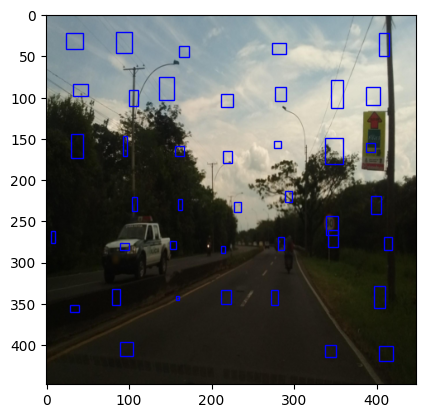

Train mAP: 0.659999430179596
[Epoch 1 / 1000]


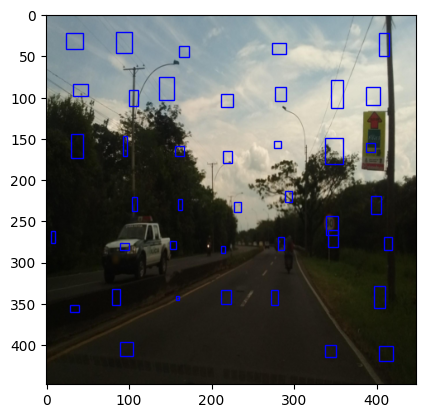

Train mAP: 0.6933327317237854
[Epoch 2 / 1000]


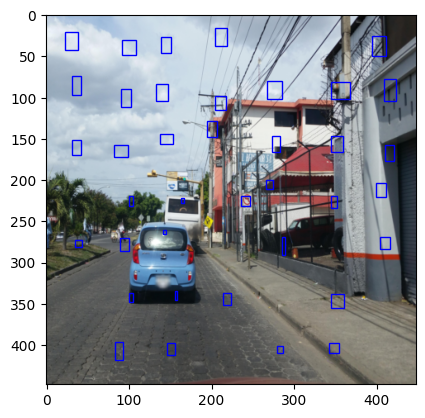

Train mAP: 0.5027774572372437
[Epoch 3 / 1000]


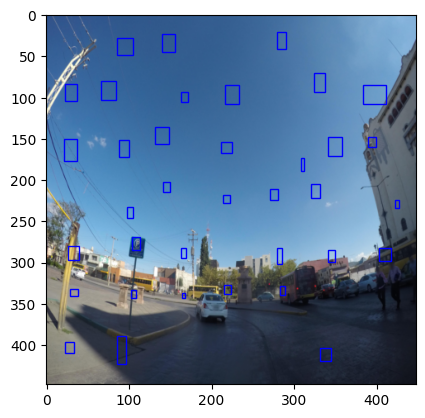

Train mAP: 0.3949997127056122
[Epoch 4 / 1000]


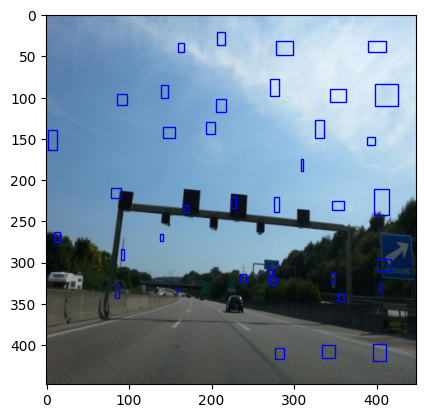

Train mAP: 0.7022215723991394
[Epoch 5 / 1000]


KeyboardInterrupt: 

In [14]:
train_dataset = TSDataSet(
    "./Yolo_Test_Data/tiny_train.csv",
    transform=transform,
    img_dir=IMG_DIR,
    label_dir=LABEL_DIR,
    split_size=SPLIT_SIZE,
    n_box=N_BOX,
    n_class=N_CLASS
)

test_dataset = TSDataSet(
    "./Yolo_Test_Data/tiny_test.csv",
    transform=transform,
    img_dir=IMG_DIR,
    label_dir=LABEL_DIR,
    split_size=SPLIT_SIZE,
    n_box=N_BOX,
    n_class=N_CLASS
)

train_loader = DataLoader(
    dataset=train_dataset,
    batch_size=BATCH_SIZE,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
    shuffle=True,
    drop_last=True,
)

test_loader = DataLoader(
    dataset=test_dataset,
    batch_size=BATCH_SIZE,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
    shuffle=True,
    drop_last=True,
)

for epoch in range(EPOCHS):
    print(f"[Epoch {epoch} / {EPOCHS}]")

    pred_boxes, target_boxes, last_item, last_boxes = get_bboxes(
        test_loader,
        model,
        iou_threshold=0.6,
        threshold=0.4,
        split_size=SPLIT_SIZE,
        n_class=N_CLASS,
        device = device
    )

    mean_avg_prec = mean_average_precision(
        pred_boxes, target_boxes, iou_threshold=0.2, box_format="midpoint"
    )


    plot_image_with_bbox(last_item[0].permute(1,2,0).to("cpu"), last_boxes[0])


    print(f"Train mAP: {mean_avg_prec}")

    # if epoch % 20 == 0:
    #    checkpoint = {
    #        "state_dict": model.state_dict(),
    #        "optimizer": optimizer.state_dict(),
    #    }
    #    save_checkpoint(checkpoint, filename=LOAD_MODEL_FILE)
    #    time.sleep(10)


    # torch.cuda.empty_cache()
    # train_fn(train_loader, model, optimizer, loss_fn)


## Now Let's use our camera to detect objects

In [15]:
# Classes
nc = 76  # number of classes
names = [
  "regulatory--keep-right", "regulatory--height-limit", "warning--railroad-crossing-with-barriers", "warning--falling-rocks-or-debris-right",
  "regulatory--yield", "warning--curve-right", "regulatory--pedestrians-only", "warning--pedestrians-crossing", "regulatory--no-entry",
  "warning--slippery-road-surface", "warning--curve-left", "information--parking", "information--tram-bus-stop", "warning--crossroads",
  "regulatory--stop", "regulatory--maximum-speed-limit", "regulatory--turn-right", "warning--roundabout", "warning--road-bump",
  "warning--uneven-road", "warning--railroad-crossing-without-barriers", "regulatory--bicycles-only", "regulatory--yield-to-oncoming-traffic",
  "regulatory--shared-path-pedestrians-and-bicycles", "regulatory--no-bicycles", "regulatory--no-pedestrians", "regulatory--no-overtaking",
  "regulatory--keep-left", "regulatory--go-straight", "regulatory--no-parking", "regulatory--no-right-turn", "regulatory--no-left-turn",
  "complementary--chevron-left", "regulatory--no-heavy-goods-vehicles", "regulatory--weight-limit", "regulatory--no-u-turn",
  "warning--other-danger", "warning--junction-with-a-side-road-perpendicular-right", "warning--double-curve-first-right",
  "regulatory--turn-left", "warning--roadworks", "warning--children", "warning--traffic-merges-right", "warning--road-narrows-right",
  "information--motorway", "regulatory--pass-on-either-side", "warning--bicycles-crossing", "complementary--distance",
  "regulatory--go-straight-or-turn-right", "regulatory--go-straight-or-turn-left", "regulatory--no-motor-vehicles",
  "complementary--chevron-right", "information--disabled-persons", "regulatory--no-goods-vehicles", "regulatory--roundabout",
  "regulatory--no-goods-vehicles-exceeding-limit", "warning--traffic-signals", "warning--road-narrows", "warning--road-narrows-left",
  "information--gas-station","regulatory--axel-mass-limit","warning--delineator","warning--wild-animals","warning--domestic-animals",
  "regulatory--turn-left-or-right","warning--road-slope-left","warning--double-curve-first-left","regulatory--no-buses",
  "warning--falling-rocks-or-debris-left","warning--delineator--right","warning--delineator--left","warning--junction-with-a-side-road-perpendicular-left",
  "warning--road-dip","warning--road-slope-right","warning--traffic-merges-left","information--hospital"
]

##### predict from live video

In [17]:
# color for each class
colors = np.random.uniform(0, 255, size=(nc, 3))

# image pre-processing 
def process_img(frame, model):
    if frame.shape[2] == 3:
        frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB) 
    frame = Image.fromarray(frame)
    frame = cv2.resize(np.array(frame), (448, 448))
    transform = transforms.Compose([transforms.ToTensor()])
    frame = transform(frame).unsqueeze(0)
  
    #------------(prediction)------------#
    model = model.to("cuda")
    frame = frame.to("cuda")
    model.eval()
    with torch.no_grad():
        preds = model(frame)
    
    #------------(let's extract bbox infos)------------#
    bboxes = cellboxes_to_boxes(preds, split_size=7, n_class=76)
    #bboxes = non_max_suppression(bboxes[0], iou_threshold=0.7, drop_threshold=0.4, box_format="midpoint")
    
    for idx in range(len(bboxes)):
        bboxes = non_max_suppression(bboxes[idx], iou_threshold=0.7, drop_threshold=0.5, box_format="midpoint")
    return (bboxes, frame)
    

# Create a VideoCapture object to access the camera
cap = cv2.VideoCapture(0) 

# in case the video capture is not working or busy then exit
if not cap.isOpened():
    print("Error: Could not open the camera.")
    exit(0)
font = cv2.FONT_HERSHEY_SIMPLEX

while True:
    # Read a frame from the camera
    ret, frame = cap.read()
    
    # in case no frame was captured then break
    if not ret:
        print("Error: Failed to grab a frame.")
        break
    
    # processing the frame (single image from capture)
    bboxes, img = process_img(frame, model) 
    
    # to draw the boxes correctly we have to calculate the scale-factor
    W, H, _ = frame.shape

    W_sf = W / 448
    H_sf = H / 448

    for box in bboxes:
        idx, prob, x, y, w, h = box
        print(f"x = {x}, y = {y}, w = {w}, h = {h}")
        x = int(np.round(x * 448 * W_sf))
        y = int(np.round(y * 448 * H_sf))
        w = int(np.round(w * 448 * W_sf))
        h = int(np.round(h * 448 * H_sf))
        # x = int(x * 448 * W_sf)
        # y = int(y * 448 * H_sf)
        # w = int(w * 448 * W_sf)
        # h = int(h * 448 * H_sf)
        print(f"x = {x}, y = {y}, w = {w}, h = {h}")
        color = colors[int(idx)]
        label = names[int(idx)]
        cv2.rectangle(frame, (x, y), (x + w, y + h), color, 2)
        cv2.putText(frame, label, (x, y + 30), font, 0.5, color, 1)

    # Display the frame in a window
    cv2.imshow("Live Video", frame)
    #break
    # Exit the loop and close the window if 'q' key is pressed
    if cv2.waitKey(1) & 0xFF == ord('q'):
        break

# Release the VideoCapture and close the window
cap.release()
cv2.destroyAllWindows()

x = 0.6345316767692566, y = 0.1869945228099823, w = 0.04785578325390816, h = 0.06649073958396912
x = 305, y = 120, w = 23, h = 43
x = 0.6311151385307312, y = 0.2054772824048996, w = 0.053166233003139496, h = 0.07263176143169403
x = 303, y = 132, w = 26, h = 46
x = 0.7455453276634216, y = 0.3289472758769989, w = 0.07320775836706161, h = 0.10118564963340759
x = 358, y = 211, w = 35, h = 65
x = 0.644819974899292, y = 0.18709176778793335, w = 0.05423140898346901, h = 0.09419760853052139
x = 310, y = 120, w = 26, h = 60
x = 0.6552549600601196, y = 0.40174758434295654, w = 0.046324100345373154, h = 0.06660208851099014
x = 315, y = 257, w = 22, h = 43
x = 0.544614315032959, y = 0.2355094850063324, w = 0.04259117320179939, h = 0.06259370595216751
x = 261, y = 151, w = 20, h = 40
x = 0.634008526802063, y = 0.24095453321933746, w = 0.04666141793131828, h = 0.08102879673242569
x = 304, y = 154, w = 22, h = 52
x = 0.7800853848457336, y = 0.7759406566619873, w = 0.060326386243104935, h = 0.10394651

#### dummy test of the model

In [ ]:
# image
some_images = ["-LfQEKzKsblbDtQzBZGY4Q.jpg",
                "-Lnqtnmhg5a0Geqyn4m_gQ.jpg",
                "-LQAjPpM4ZlWbR_GiEo-5Q.jpg",
                "-LqxrUMrnqvpRpiyYFMT6g.jpg",
                "-LQXWLyVw_nMfog6Sya92w.jpg",
                "-LtOhSguWQXyerbzUN6HpA.jpg",
                "-lw3mUDZ56348AA7xtiZ6Q.jpg",
                "-L_MxrOq7gnQl3v6WjDdwg.jpg",
                "-MGHrk6ifhEZhWCjotCb4A.jpg",
                "-mlRH8YvhrjGIMy8M80Itg.jpg",
                "-MlU-jgd1aUWgzCSIEi1Yg.jpg",
                "-mSYxRe0B2czxBN1NnaLpA.jpg",
                "-mZ3FS4JXBPkJJKvF2U8-A.jpg",
                "-NaZlwuVvELCGEN3IOa08Q.jpg",
                "-NDdpaJqS5GOM-CBrnwifg.jpg",
                "-nkXI9G16ok56ioLAIfMjQ.jpg",
                "-NQmKWfAuPWZt3s7WrwAuQ.jpg",
                "-NRs2TX8kBnmjWDeqs7o_A.jpg",
                "-nvTzJ-2am0mxQPqnZzZBA.jpg",
                "-o4-dLzOXoOSOdR4P9ZGtA.jpg",
                "-OG52dnk6NNuOkNxA-H3jQ.jpg",]
for i in range(10):
    frame = cv2.imread(f"./Yolo_Test_Data/images/{some_images[i]}") 
    
    # processing the frame (single image from capture)
    bboxes, img = process_img(frame, model) 
    
    # to draw the boxes correctly we have to calculate the scale-factor
    W, H, _ = frame.shape
    frame = cv2.cvtColor(frame, cv2.COLOR_RGB2BGR) 
    
    W_sf = W / 448
    H_sf = H / 448
    
    for box in bboxes:
        idx, prob, x, y, w, h = box
        print(f"x = {x}, y = {y}, w = {w}, h = {h}")
        x = int(np.round(x * 448 * W_sf))
        y = int(np.round(y * 448 * H_sf))
        w = int(np.round(w * 448 * W_sf))
        h = int(np.round(h * 448 * H_sf))
        print(f"x = {x}, y = {y}, w = {w}, h = {h}")
        color = colors[int(idx)]
        label = names[int(idx)]
        cv2.rectangle(frame, (x, y), (x + w, y + h), color, 2)
        cv2.putText(frame, label, (x, y + 30), font, 0.5, color, 1)
    # Display the frame in a window
    plt.imshow(frame)
    plt.axis("off")  
    plt.show()